
# Experiment No. 9

## Image Classification Using CNN and Keras
### Aim
To classify handwritten digits (0–9) from the MNIST dataset using a Convolutional Neural Network (CNN) implemented with Keras and evaluate its classification accuracy.


## Theory
The MNIST dataset consists of 60,000 training images and 10,000 testing images of handwritten digits from 0 to 9. Each image is a 28 × 28 grayscale image.

A Convolutional Neural Network (CNN) is a deep learning model designed for image recognition. It automatically learns important image features such as edges, curves, and shapes.

The Conv2D layer extracts features, MaxPooling2D reduces spatial dimensions, Flatten converts feature maps into a vector, and Dense layers perform classification. The Softmax activation function produces probabilities for the ten digit classes.

Before training, pixel values are normalized from the range 0–255 to 0–1. The digit labels are converted into one-hot encoded vectors. The model is trained using the Adam optimizer and categorical cross-entropy loss. Finally, its performance is evaluated using test accuracy.

Import required libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical

print("Tensorflow version:", tf.__version__)

Tensorflow version: 2.21.0


Load the MNIST dataset

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Display sample images

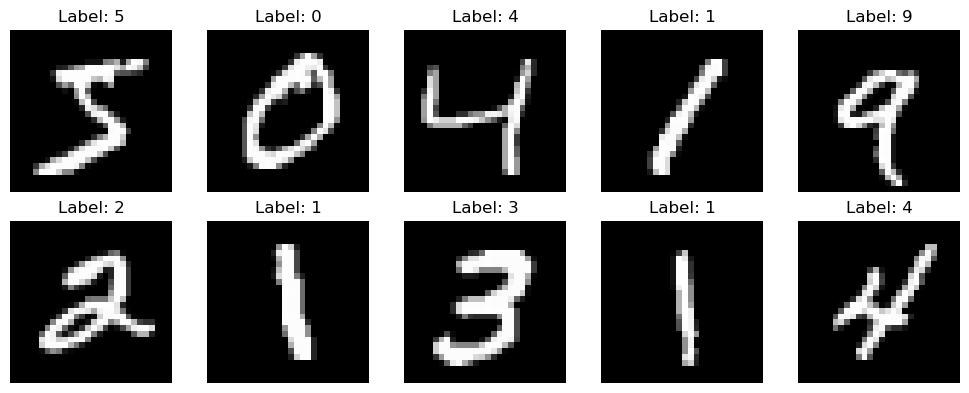

In [5]:

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Normalize and reshape the images

In [6]:
# Normalize pixel values to the range 0 to 1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add the greyScale channel dimension
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training images Shape:", x_train.shape)
print("Testing images shape:", x_test.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Training images Shape: (60000, 28, 28, 1)
Testing images shape: (10000, 28, 28, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


One-hot encode the labels

In [7]:
y_train_cat = to_categorical(y_train, num_classes=10)
y_test_cat = to_categorical(y_test, num_classes=10)

print("Original label:", y_train[0])
print("One-hot encoded label:", y_train_cat[0])
print("Encoded labels shape:", y_train_cat.shape)

Original label: 5
One-hot encoded label: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
Encoded labels shape: (60000, 10)


Build the CNN model

In [8]:
model = Sequential([
    Conv2D(32, (3,3), activation="relu",
           input_shape=(28, 28, 1)),
    
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

model.summary()

d:\Anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

Compile the model

In [9]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


Train the CNN

In [12]:
history = model.fit(
    x_train,
    y_train_cat,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - accuracy: 0.9260 - loss: 0.2538 - val_accuracy: 0.9815 - val_loss: 0.0649
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.9797 - loss: 0.0653 - val_accuracy: 0.9843 - val_loss: 0.0546
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 15s 34ms/step - accuracy: 0.9866 - loss: 0.0454 - val_accuracy: 0.9857 - val_loss: 0.0489
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.9891 - loss: 0.0360 - val_accuracy: 0.9890 - val_loss: 0.0377
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - accuracy: 0.9912 - loss: 0.0291 - val_accuracy: 0.9888 - val_loss: 0.0383


Plot training and validation accuracy

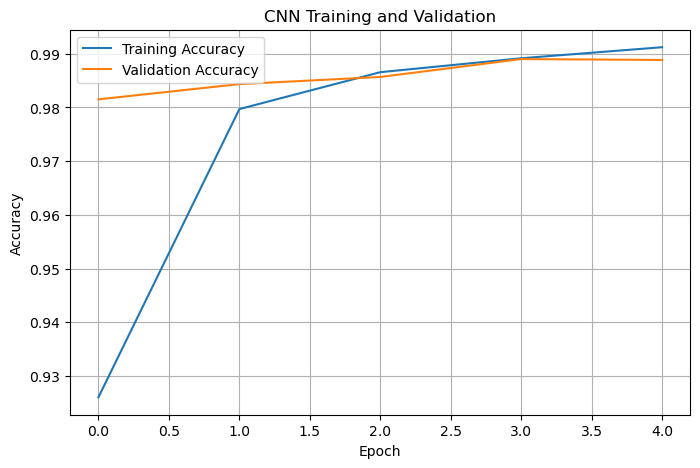

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Training and Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Plot training and validation loss

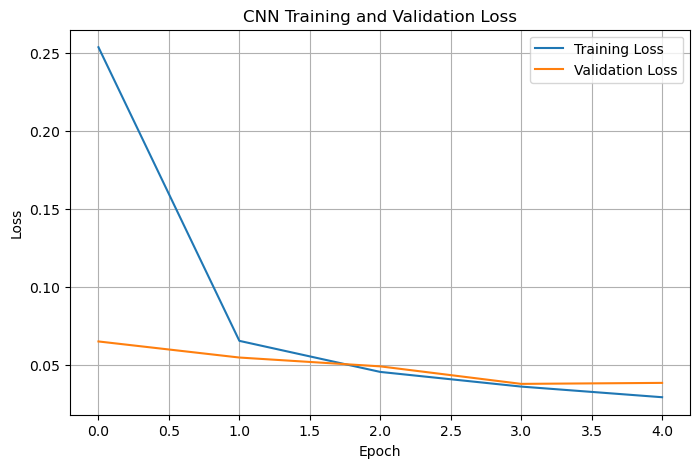

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

Evaluate the model on the test dataset

In [15]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test_cat,
    verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Test Loss: 0.0326
Test Accuracy: 98.94 %


Predict a handwritten digit

In [16]:
predictions = model.predict(x_test[:10], verbose=0)

predicted_labels = np.argmax(predictions, axis=1)
actual_labels = y_test[:10]

print("Predicted labels:", predicted_labels)
print("Actual labels:  ", actual_labels)

Predicted labels: [7 2 1 0 4 1 4 9 5 9]
Actual labels:   [7 2 1 0 4 1 4 9 5 9]


Display predictions with images

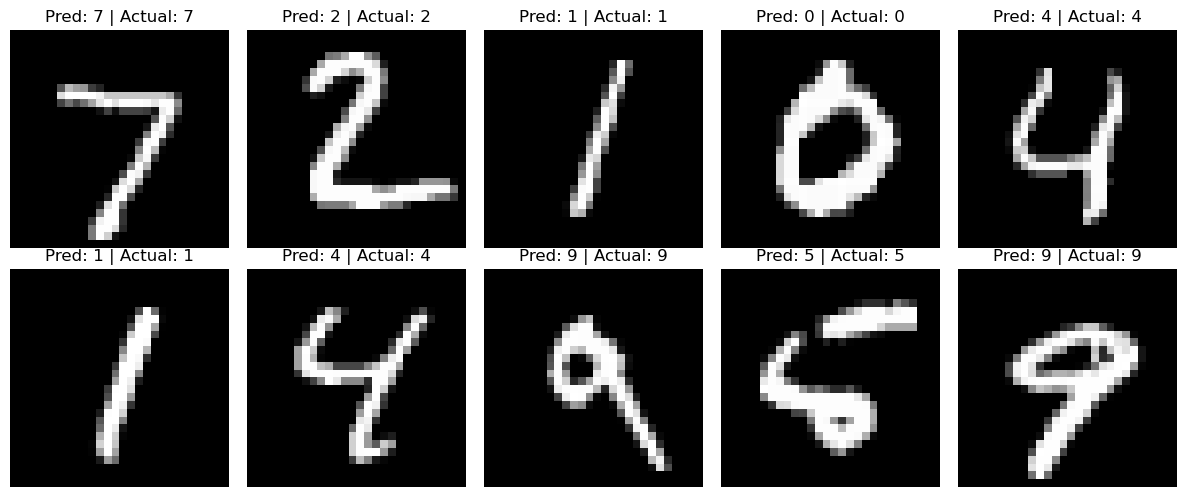

In [17]:

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")

    predicted = predicted_labels[i]
    actual = actual_labels[i]

    plt.title(f"Pred: {predicted} | Actual: {actual}")
    plt.axis("off")

plt.tight_layout()
plt.show()


## Conclusion

A Convolutional Neural Network was implemented using TensorFlow and Keras to classify handwritten digits from the MNIST dataset. The images were normalized and reshaped, and their labels were converted into one-hot encoded vectors. The CNN was trained using the Adam optimizer and categorical cross-entropy loss. Its performance was evaluated on the test dataset using accuracy and loss. The experiment demonstrates the effectiveness of CNNs for handwritten digit recognition.